# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Perez Lopez Fernando Emmanuel   
**Grupo:** 511  **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display

pd.set_option("display.max_columns", None)

ruta = "../data/raw/nyc_taxi_examen.csv"
df = pd.read_csv(ruta)

display(df.head())
print("Filas y columnas:", df.shape)
print("Columnas:", df.columns.tolist())
df.info()

display(df.describe().round(2))

print("Valores existentes en payment_type:", df["payment_type"].unique())
display(df["payment_type"].value_counts(dropna=False).to_frame(name="Cantidad de viajes"))

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Filas y columnas: (2427612, 20)
Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']
<class 'pandas.DataFrame'>
RangeIndex: 2427612 entries, 0 to 2427611
Data columns (total 20 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   str    
 2   tpep_dropoff_datetime  str    
 3   passenger_count        float64
 4   trip_distance          float64
 5   RatecodeID             float64
 6   PULocationID           float64
 7   DOLocationID           float64
 8   payment_type           float64
 9   fare_amount            float64
 10  extra                  float64
 11  mta_tax                float64
 12  tip

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415487.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,1.17,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,0.46,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,1.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,1.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,1.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,4.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67


Valores existentes en payment_type: [ 1.  2. nan  4.  3.]


,Cantidad de viajes
payment_type,
1.0,2051983
2.0,329533
4.0,23558
NaN,12125
3.0,10413


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [6]:
df_limpio = df.copy()

print("Dimensiones antes de limpiar:", df_limpio.shape)
print("Valores nulos por columna:")
display(df_limpio.isnull().sum().to_frame("faltantes"))
print("Registros duplicados:", df_limpio.duplicated().sum())

df_limpio = df_limpio.drop_duplicates().copy()
print("Filas sin duplicados:", len(df_limpio))
df_limpio = df_limpio.dropna().copy()
print("Filas sin valores nulos:", len(df_limpio))

df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0)
    & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0)
    & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
].copy()

print("Dimensiones después de limpiar:", df_limpio.shape)
print("Registros restantes:", len(df_limpio))
print("Nulos restantes:", df_limpio.isnull().sum().sum())
print("Duplicados restantes:", df_limpio.duplicated().sum())

Dimensiones antes de limpiar: (2427612, 20)
Valores nulos por columna:


,faltantes
VendorID,0
tpep_pickup_datetime,12126
tpep_dropoff_datetime,12127
passenger_count,12123
trip_distance,12142
RatecodeID,12138
PULocationID,12125
DOLocationID,12137
payment_type,12125
fare_amount,12124


Registros duplicados: 11961
Filas sin duplicados: 2415651
Filas sin valores nulos: 2196158
Dimensiones después de limpiar: (2096600, 20)
Registros restantes: 2096600
Nulos restantes: 0
Duplicados restantes: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [7]:
df_limpio["payment_type"] = df_limpio["payment_type"].replace({2: "Cash"})
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()

variables_modelo = ["passenger_count", "trip_distance"]
X = df_cash[variables_modelo].copy()

print("Viajes pagados en efectivo:", len(df_cash))
display(X.head())
display(X.describe().round(2))

Viajes pagados en efectivo: 282085


,passenger_count,trip_distance
22,1.0,3.00
45,1.0,4.20
55,1.0,0.99
82,1.0,10.93
126,1.0,0.66


,passenger_count,trip_distance
count,282085.00,282085.00
mean,1.34,3.84
std,0.76,6.21
min,1.00,0.01
25%,1.00,0.92
50%,1.00,1.70
75%,1.00,4.37
max,6.00,1686.49


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [8]:
X_log = np.log1p(X)

escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_log)
X_escalado = pd.DataFrame(X_escalado, columns=variables_modelo, index=X.index)

print("Resumen después de log1p:")
display(X_log.describe().round(3))
print("Resumen después de estandarizar:")
display(X_escalado.describe().round(3))

print("Promedio y desviación estándar de las variables estandarizadas:")
display(pd.DataFrame({
    "promedio": X_escalado.mean(),
    "desviación estándar": X_escalado.std(ddof=0)
}).round(3))

Resumen después de log1p:


,passenger_count,trip_distance
count,282085.000,282085.000
mean,0.815,1.225
std,0.250,0.763
min,0.693,0.010
25%,0.693,0.652
50%,0.693,0.993
75%,0.693,1.681
max,1.946,7.431


Resumen después de estandarizar:


,passenger_count,trip_distance
count,282085.000,282085.000
mean,-0.000,0.000
std,1.000,1.000
min,-0.486,-1.592
25%,-0.486,-0.751
50%,-0.486,-0.304
75%,-0.486,0.597
max,4.520,8.130


Promedio y desviación estándar de las variables estandarizadas:


,promedio,desviación estándar
passenger_count,-0.0,1.0
trip_distance,0.0,1.0


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,324581.9399,0.5503
1,3,160363.1884,0.6117
2,4,115075.5831,0.6202
3,5,86895.8983,0.6249
4,6,61144.8891,0.5617


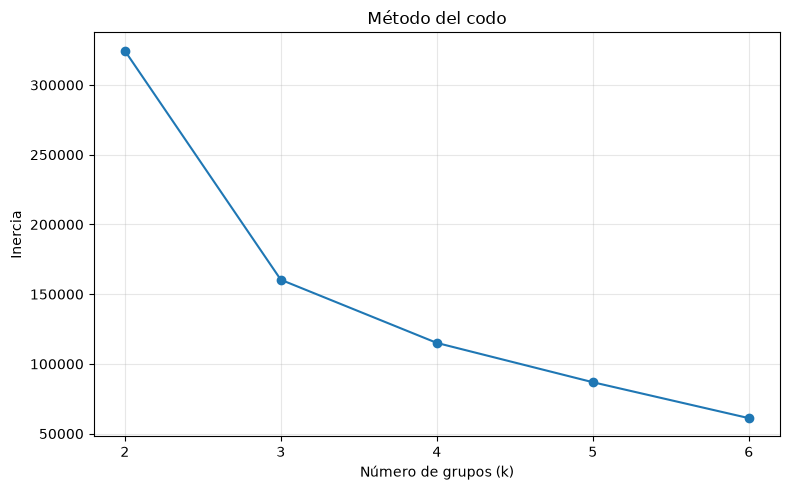

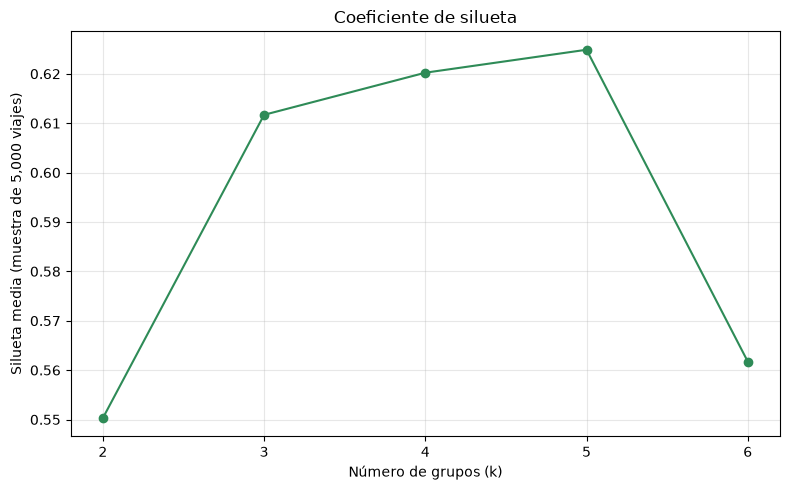

In [9]:
valores_k = range(2, 7)
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    grupos = modelo.fit_predict(X_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(
        X_escalado, grupos, sample_size=5000, random_state=42
    ))

resultados = pd.DataFrame({
    "k": list(valores_k),
    "Inercia": inercias,
    "Silueta": siluetas
})
display(resultados.round(4))

plt.figure(figsize=(8, 5))
plt.plot(resultados["k"], resultados["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(resultados["k"], resultados["Silueta"], marker="o", color="seagreen")
plt.title("Coeficiente de silueta")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Silueta media (muestra de 5,000 viajes)")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

k elegido: 5
Silueta: 0.6249


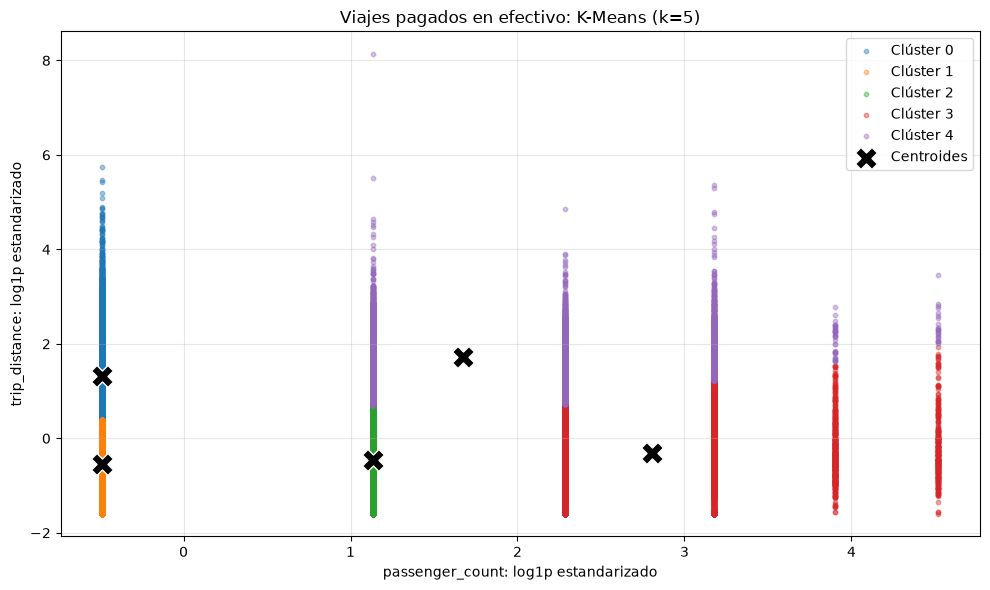

In [ ]:
fila_mejor = resultados["Silueta"].idxmax()
k_elegido = int(resultados.loc[fila_mejor, "k"])
print("k elegido:", k_elegido)
print("Silueta:", round(resultados.loc[fila_mejor, "Silueta"], 4))

modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(10, 6))
for grupo in range(k_elegido):
    puntos = X_escalado[etiquetas == grupo]
    plt.scatter(
        puntos["passenger_count"], puntos["trip_distance"],
        s=10, alpha=0.4, color=plt.get_cmap("tab10")(grupo),
        label=f"Clúster {grupo}"
    )

plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker="X", s=250, color="black", edgecolor="white",
    label="Centroides", zorder=3
)
plt.title(f"Viajes pagados en efectivo: K-Means (k={k_elegido})")
plt.xlabel("passenger_count: log1p estandarizado")
plt.ylabel("trip_distance: log1p estandarizado")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [11]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

resumen = df_resultado.groupby("cluster").agg(
    Cantidad_viajes=("passenger_count", "size"),
    Pasajeros_media=("passenger_count", "mean"),
    Pasajeros_mediana=("passenger_count", "median"),
    Distancia_media=("trip_distance", "mean"),
    Distancia_mediana=("trip_distance", "median")
)

print("Estadísticos en unidades originales: pasajeros y millas.")
display(resumen.round(2))

Estadísticos en unidades originales: pasajeros y millas.


,Cantidad_viajes,Pasajeros_media,Pasajeros_mediana,Distancia_media,Distancia_mediana
cluster,,,,,
0,60035,1.0,1.0,9.54,7.95
1,160283,1.0,1.0,1.36,1.20
2,28514,2.0,2.0,1.58,1.31
3,16904,3.6,4.0,1.97,1.48
4,16349,2.5,2.0,13.14,11.51


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**
Elegí k = 5 porque obtuvo la mayor silueta de 0.6249 y una inercia de 86,895.90. Aunque el codo aparece cerca de k = 3, cinco grupos permiten distinguir mejor los tipos de viajes. Con k = 6 la inercia disminuye, pero la silueta baja a 0.5617.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**
Clúster 0, viajes largos de un pasajero: tiene 60,035 viajes. La media y la mediana son de 1 pasajero. La distancia media es de 9.54 millas y la mediana es de 7.95 millas.

Clúster 1, viajes cortos de un pasajero: tiene 160,283 viajes. La media y la mediana son de 1 pasajero. La distancia media es de 1.36 millas y la mediana es de 1.20 millas.

Clúster 2, viajes cortos de dos pasajeros: tiene 28,514 viajes. La media y la mediana son de 2 pasajeros. La distancia media es de 1.58 millas y la mediana es de 1.31 millas.

Clúster 3, viajes cortos con más pasajeros: tiene 16,904 viajes. La media es de 3.60 pasajeros y la mediana es de 4. La distancia media es de 1.97 millas y la mediana es de 1.48 millas.

Clúster 4, viajes largos de varios pasajeros: tiene 16,349 viajes. La media es de 2.50 pasajeros y la mediana es de 2. La distancia media es de 13.14 millas y la mediana es de 11.51 millas.

**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:**
Los clústeres 0 y 1 tienen el menor promedio, con 1 pasajero, pero sus distancias medias son de 9.54 y 1.36 millas. El clúster 3 tiene el mayor promedio, con 3.60 pasajeros, y recorre 1.97 millas en promedio. Tener más pasajeros no implica recorrer más distancia.

**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:**
No. El clúster 3 tiene más pasajeros, con un promedio de 3.60, pero recorre 1.97 millas. El clúster 4 tiene menos pasajeros, con un promedio de 2.50, y recorre 13.14 millas. La gráfica también muestra distintas distancias para una misma cantidad de pasajeros.

---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**